# Predicting Car Price Classes with Logistic Regression

This notebook treats car price as a classification problem: each car is put into one of four price classes, and our own logistic regression class (`src/logistic_regression.py`) learns to predict the class. The data exploration and the reasons behind each cleaning step are in `A1_car_price_prediction.ipynb` and are not repeated here.

In [1]:
import sys
sys.path.append('..')

import logging
import warnings

import joblib
import mlflow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlflow import MlflowClient
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

from src.preprocessing import clean_car_data, fit_impute_stats, encode_for_model, fit_scaler, apply_scaler
from src.logistic_regression import LogisticRegression
from src.regularization import RidgePenalty
from src.experiment import setup_mlflow

# Show only MLflow's errors, not its info notes
logging.getLogger('mlflow').setLevel(logging.ERROR)

## Load, clean and split

In [2]:
df = pd.read_csv('../data/raw/cars.csv')
# Same cleaning as before
df_clean = clean_car_data(df)

X = df_clean.drop(columns=['selling_price'])
y = df_clean['selling_price']
# Same split as before: 20% test, random_state=42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(df.shape, '->', df_clean.shape)

(8128, 13) -> (6827, 12)


## Price classes

We cut the price at the 25%, 50% and 75% points of the training prices, so each class holds about a quarter of the training cars (a car priced exactly on a cut point goes into the higher class). Class 0 is the cheapest quarter and class 3 the most expensive. The cut points come from the training cars only, and the test cars use the same ones.

`pd.cut(price, 4)` would make four classes of equal price width instead. Because a few cars are very expensive, almost every car would land in class 0, and a model could look good by always guessing class 0.

In [3]:
# Price cut points from the training cars only
edges = np.quantile(y_train, [0.25, 0.5, 0.75])
# Each price becomes the number of cut points below it: 0, 1, 2 or 3
c_train = np.digitize(y_train, edges)
c_test = np.digitize(y_test, edges)

print('cut points (₹):', edges)
print('training cars per class:', np.bincount(c_train))
print('test cars per class:    ', np.bincount(c_test))
print('pd.cut(price, 4) on all cars:', np.bincount(pd.cut(y, 4, labels=False)))

cut points (₹): [250000. 415000. 650000.]
training cars per class: [1352 1377 1351 1381]
test cars per class:     [329 380 348 309]
pd.cut(price, 4) on all cars: [6747   63   16    1]


## Validation rows and encoding

To pick the best model we hold back 20% of the training cars as validation rows. The test set is used only once, at the end. Missing values are filled with medians, categories become yes/no columns and numbers are scaled, all learned from the remaining training rows only.

In [4]:
X_fit, X_val, c_fit, c_val = train_test_split(X_train, c_train, test_size=0.2, random_state=42)

# Medians, column list and scaling learned from the fitting rows only
impute_stats = fit_impute_stats(X_fit)
feature_columns = list(encode_for_model(X_fit, impute_stats).columns)
scaler_stats = fit_scaler(encode_for_model(X_fit, impute_stats))


def prepare(rows):
    # Fill gaps, one-hot encode with the fixed column list, scale, then plain numbers
    encoded = encode_for_model(rows, impute_stats, feature_columns)
    return apply_scaler(encoded, scaler_stats).to_numpy(dtype=float)


A_fit, A_val, A_test = prepare(X_fit), prepare(X_val), prepare(X_test)
print('fitting rows:', A_fit.shape, '| validation rows:', A_val.shape, '| test rows:', A_test.shape)

fitting rows: (4368, 39) | validation rows: (1093, 39) | test rows: (1366, 39)


## Task 1: classification metrics from scratch

Our class has its own `accuracy`, `precision`, `recall`, `f1`, `macro_*` and `weighted_*` methods, and a `classification_report` method that puts them into one table. We compare it with sklearn's on made-up labels.

The weighted scores weight each class by its share of the true labels. These shares already add up to 1, so we do not divide by 4 again (the formula in the instructions does, but sklearn doesn't).

In [5]:
# Made-up true and predicted labels for 4 classes
rng = np.random.default_rng(0)
y_true = rng.integers(0, 4, 200)
y_pred = np.where(rng.random(200) < 0.6, y_true, rng.integers(0, 4, 200))  # about 60% copied from the truth

model = LogisticRegression(k=4)
ours = model.classification_report(y_true, y_pred)
display(ours.round(4))
print(classification_report(y_true, y_pred, digits=4))

# Same numbers from sklearn as a table, to compare every cell
theirs = pd.DataFrame(classification_report(y_true, y_pred, output_dict=True)).T
print('largest difference:', np.nanmax(np.abs(ours.drop(index='accuracy').to_numpy()
                                             - theirs.drop(index='accuracy').to_numpy())))

,precision,recall,f1-score,support
0,0.6383,0.7143,0.6742,42
1,0.5870,0.5745,0.5806,47
2,0.6000,0.6346,0.6168,52
3,0.7500,0.6610,0.7027,59
accuracy,NaN,NaN,0.6450,200
macro avg,0.6438,0.6461,0.6436,200
weighted avg,0.6492,0.6450,0.6457,200


              precision    recall  f1-score   support

           0     0.6383    0.7143    0.6742        42
           1     0.5870    0.5745    0.5806        47
           2     0.6000    0.6346    0.6168        52
           3     0.7500    0.6610    0.7027        59

    accuracy                         0.6450       200
   macro avg     0.6438    0.6461    0.6436       200
weighted avg     0.6492    0.6450    0.6457       200

largest difference: 0.0


Both tables give the same numbers.

Support is the number of rows whose true label is that class. For the average rows it is the total number of rows. The weighted averages use the support as the weights.

## Task 2 and experiments: ridge or not

Ridge adds `λ·Σθ²` to the loss (the intercept is not penalised). Our class averages the cross-entropy part over the rows, so one learning rate works for batch, mini-batch and stochastic training. This gives the same model as the instructions' loss: their λ equals our λ times the number of rows.

We try 8 settings by hand: each way of training, with and without ridge (λ = 0.001), plus a smaller learning rate and a bigger λ (0.01) for batch. Batch and mini-batch (30% of the rows per step) take 5,000 steps; stochastic takes 50,000 single-row steps, about 11 passes over the data. Each run is logged to MLflow (local experiment `st127634-a3`) and scored on the validation rows.

In [6]:
# We set it one level above this `notebooks/` folder, same as before
setup_mlflow('st127634-a3', root='..')


def already_logged(run_name):
    # True if an earlier run of this notebook already logged this run
    found = mlflow.search_runs(filter_string=f"attributes.run_name = '{run_name}' and attributes.status = 'FINISHED'")
    return not found.empty


settings = [
    # method, learning rate, λ (0 = no ridge), steps
    ('batch', 0.1, 0.0, 5000),
    ('batch', 0.5, 0.0, 5000),
    ('batch', 0.5, 0.001, 5000),
    ('batch', 0.5, 0.01, 5000),
    ('mini', 0.5, 0.0, 5000),
    ('mini', 0.5, 0.001, 5000),
    ('sto', 0.01, 0.0, 50000),
    ('sto', 0.01, 0.001, 50000),
]

models, rows = {}, []
for method, lr, lam, steps in settings:
    name = f'{method}-lr{lr}-lam{lam}'
    penalty = RidgePenalty(lam) if lam > 0 else None
    model = LogisticRegression(k=4, penalty=penalty, method=method, lr=lr, max_iter=steps, random_state=42)
    model.fit(A_fit, c_fit)
    pred = model.predict(A_val)
    scores = {'val_accuracy': model.accuracy(c_val, pred),
              'val_macro_f1': model.macro_f1(c_val, pred),
              'val_weighted_f1': model.weighted_f1(c_val, pred),
              'train_accuracy': model.accuracy(c_fit, model.predict(A_fit))}
    # Training is quick, so we always train, but only log runs that aren't in MLflow yet
    if not already_logged(name):
        with mlflow.start_run(run_name=name):
            mlflow.log_params({'method': method, 'lr': lr, 'lam': lam, 'max_iter': steps, 'ridge': lam > 0})
            mlflow.log_metrics(scores)
    models[name] = model
    rows.append({'run': name} | scores)

results = pd.DataFrame(rows).set_index('run').sort_values('val_macro_f1', ascending=False)
results.round(4)

,val_accuracy,val_macro_f1,val_weighted_f1,train_accuracy
run,,,,
mini-lr0.5-lam0.0,0.7521,0.7499,0.7509,0.7555
batch-lr0.5-lam0.0,0.7502,0.7477,0.7488,0.7541
mini-lr0.5-lam0.001,0.7484,0.7456,0.7464,0.7502
batch-lr0.1-lam0.0,0.7429,0.7402,0.7411,0.7484
batch-lr0.5-lam0.001,0.7411,0.7388,0.7397,0.7484
sto-lr0.01-lam0.0,0.7356,0.7356,0.7363,0.7440
sto-lr0.01-lam0.001,0.7347,0.7350,0.7356,0.7404
batch-lr0.5-lam0.01,0.7319,0.7266,0.7276,0.7271


best run: mini-lr0.5-lam0.0


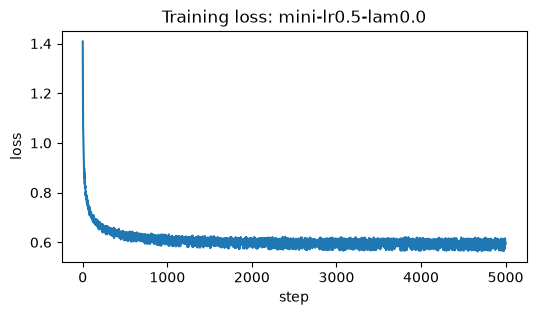

In [7]:
best_name = results.index[0]
best = models[best_name]
print('best run:', best_name)

# Loss of each update step for the best run
plt.figure(figsize=(6, 3))
plt.plot(best.losses)
plt.title(f'Training loss: {best_name}')
plt.xlabel('step')
plt.ylabel('loss')
plt.show()

## Test set (used once)

In [8]:
test_pred = best.predict(A_test)
test_report = best.classification_report(c_test, test_pred)
display(test_report.round(4))
print(classification_report(c_test, test_pred, digits=4))

,precision,recall,f1-score,support
0,0.8152,0.8450,0.8299,329
1,0.6523,0.6368,0.6445,380
2,0.6082,0.5575,0.5817,348
3,0.7642,0.8285,0.7950,309
accuracy,NaN,NaN,0.7101,1366
macro avg,0.7100,0.7169,0.7128,1366
weighted avg,0.7056,0.7101,0.7072,1366


              precision    recall  f1-score   support

           0     0.8152    0.8450    0.8299       329
           1     0.6523    0.6368    0.6445       380
           2     0.6082    0.5575    0.5817       348
           3     0.7642    0.8285    0.7950       309

    accuracy                         0.7101      1366
   macro avg     0.7100    0.7169    0.7128      1366
weighted avg     0.7056    0.7101    0.7072      1366



## Final model in MLflow

The best run's model is logged with its test scores in a run called `final model` and registered as `st127634-a3-model`, with the alias `staging`. Recent MLflow versions use aliases in place of the old "Staging" stage.

In [9]:
class CarPriceClassModel(mlflow.pyfunc.PythonModel):
    """Cleaned car rows in, price classes (0-3) out."""

    def __init__(self, model, stats):
        self.model = model
        self.stats = stats

    def predict(self, context, model_input: pd.DataFrame, params=None):
        # Same steps as in training: fill gaps, one-hot encode, scale, predict
        encoded = encode_for_model(model_input, self.stats['impute_stats'], self.stats['feature_columns'])
        return self.model.predict(apply_scaler(encoded, self.stats['scaler_stats']).to_numpy(dtype=float))


stats = {'impute_stats': impute_stats, 'feature_columns': feature_columns, 'scaler_stats': scaler_stats}
model_name = 'st127634-a3-model'

if not already_logged('final model'):
    with mlflow.start_run(run_name='final model'):
        method, lr, lam, steps = settings[[f'{s[0]}-lr{s[1]}-lam{s[2]}' for s in settings].index(best_name)]
        mlflow.log_params({'method': method, 'lr': lr, 'lam': lam, 'max_iter': steps, 'ridge': lam > 0})
        mlflow.log_metrics({'test_accuracy': best.accuracy(c_test, test_pred),
                            'test_macro_f1': best.macro_f1(c_test, test_pred),
                            'test_weighted_f1': best.weighted_f1(c_test, test_pred)}
                           | results.loc[best_name].to_dict())
        with warnings.catch_warnings():
            # MLflow notes that whole-number columns can't hold missing values; ours are never missing
            warnings.simplefilter('ignore', UserWarning)
            info = mlflow.pyfunc.log_model(
                name='model',
                python_model=CarPriceClassModel(best, stats),
                code_paths=['../src'],  # the model needs our src code to load
                input_example=X_test.head(3),
                pip_requirements=[f'numpy=={np.__version__}', f'pandas=={pd.__version__}'],
                registered_model_name=model_name,
            )
    # Point the 'staging' alias at the version just registered
    MlflowClient().set_registered_model_alias(model_name, 'staging', info.registered_model_version)

# Load the staging model back from the registry and check it predicts the same classes
loaded = mlflow.pyfunc.load_model(f'models:/{model_name}@staging')
print('same predictions after loading:', np.array_equal(loaded.predict(X_test.head(50)), test_pred[:50]))

same predictions after loading: True


In [10]:
# Everything the web app needs to turn form inputs into a price class
bundle = {'model': best, 'price_edges': [float(e) for e in edges]} | stats
joblib.dump(bundle, '../app/code/models/classifier_model.joblib')
print(sorted(bundle))

['feature_columns', 'impute_stats', 'model', 'price_edges', 'scaler_stats']


## MLflow screenshots

All runs are in the local MLflow experiment `st127634-a3`.

**All runs, sorted by validation macro F1**, with their settings. The `final model` run is the best run again, with its test scores added and the saved model linked.

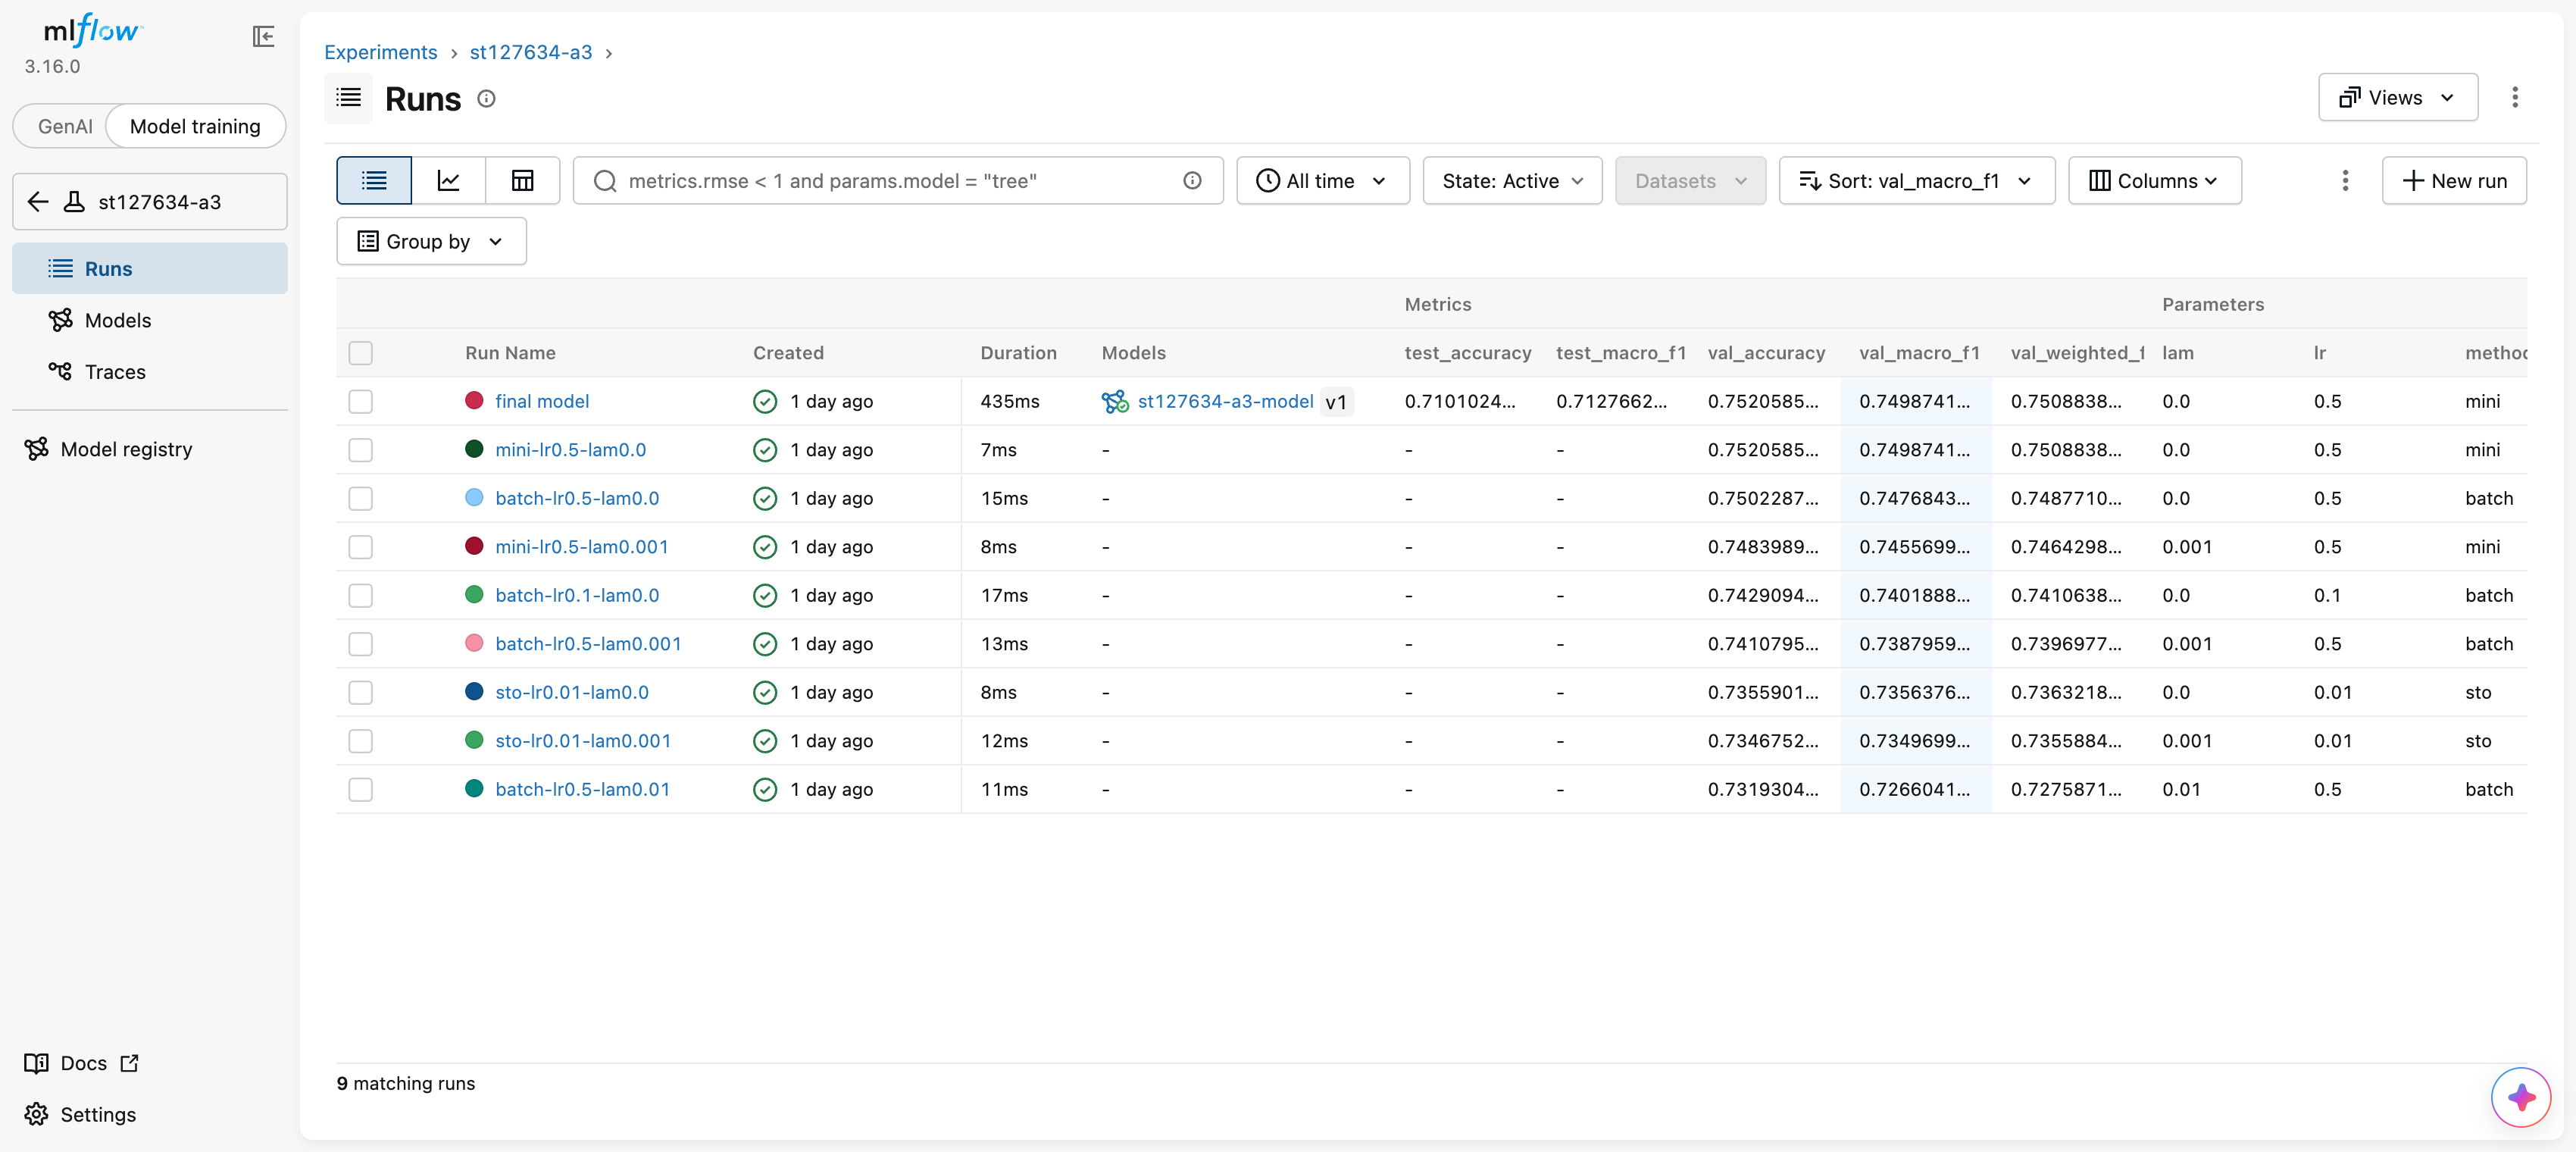

**The final model run**: test and validation scores, its setting, and the registered model `st127634-a3-model` v1.

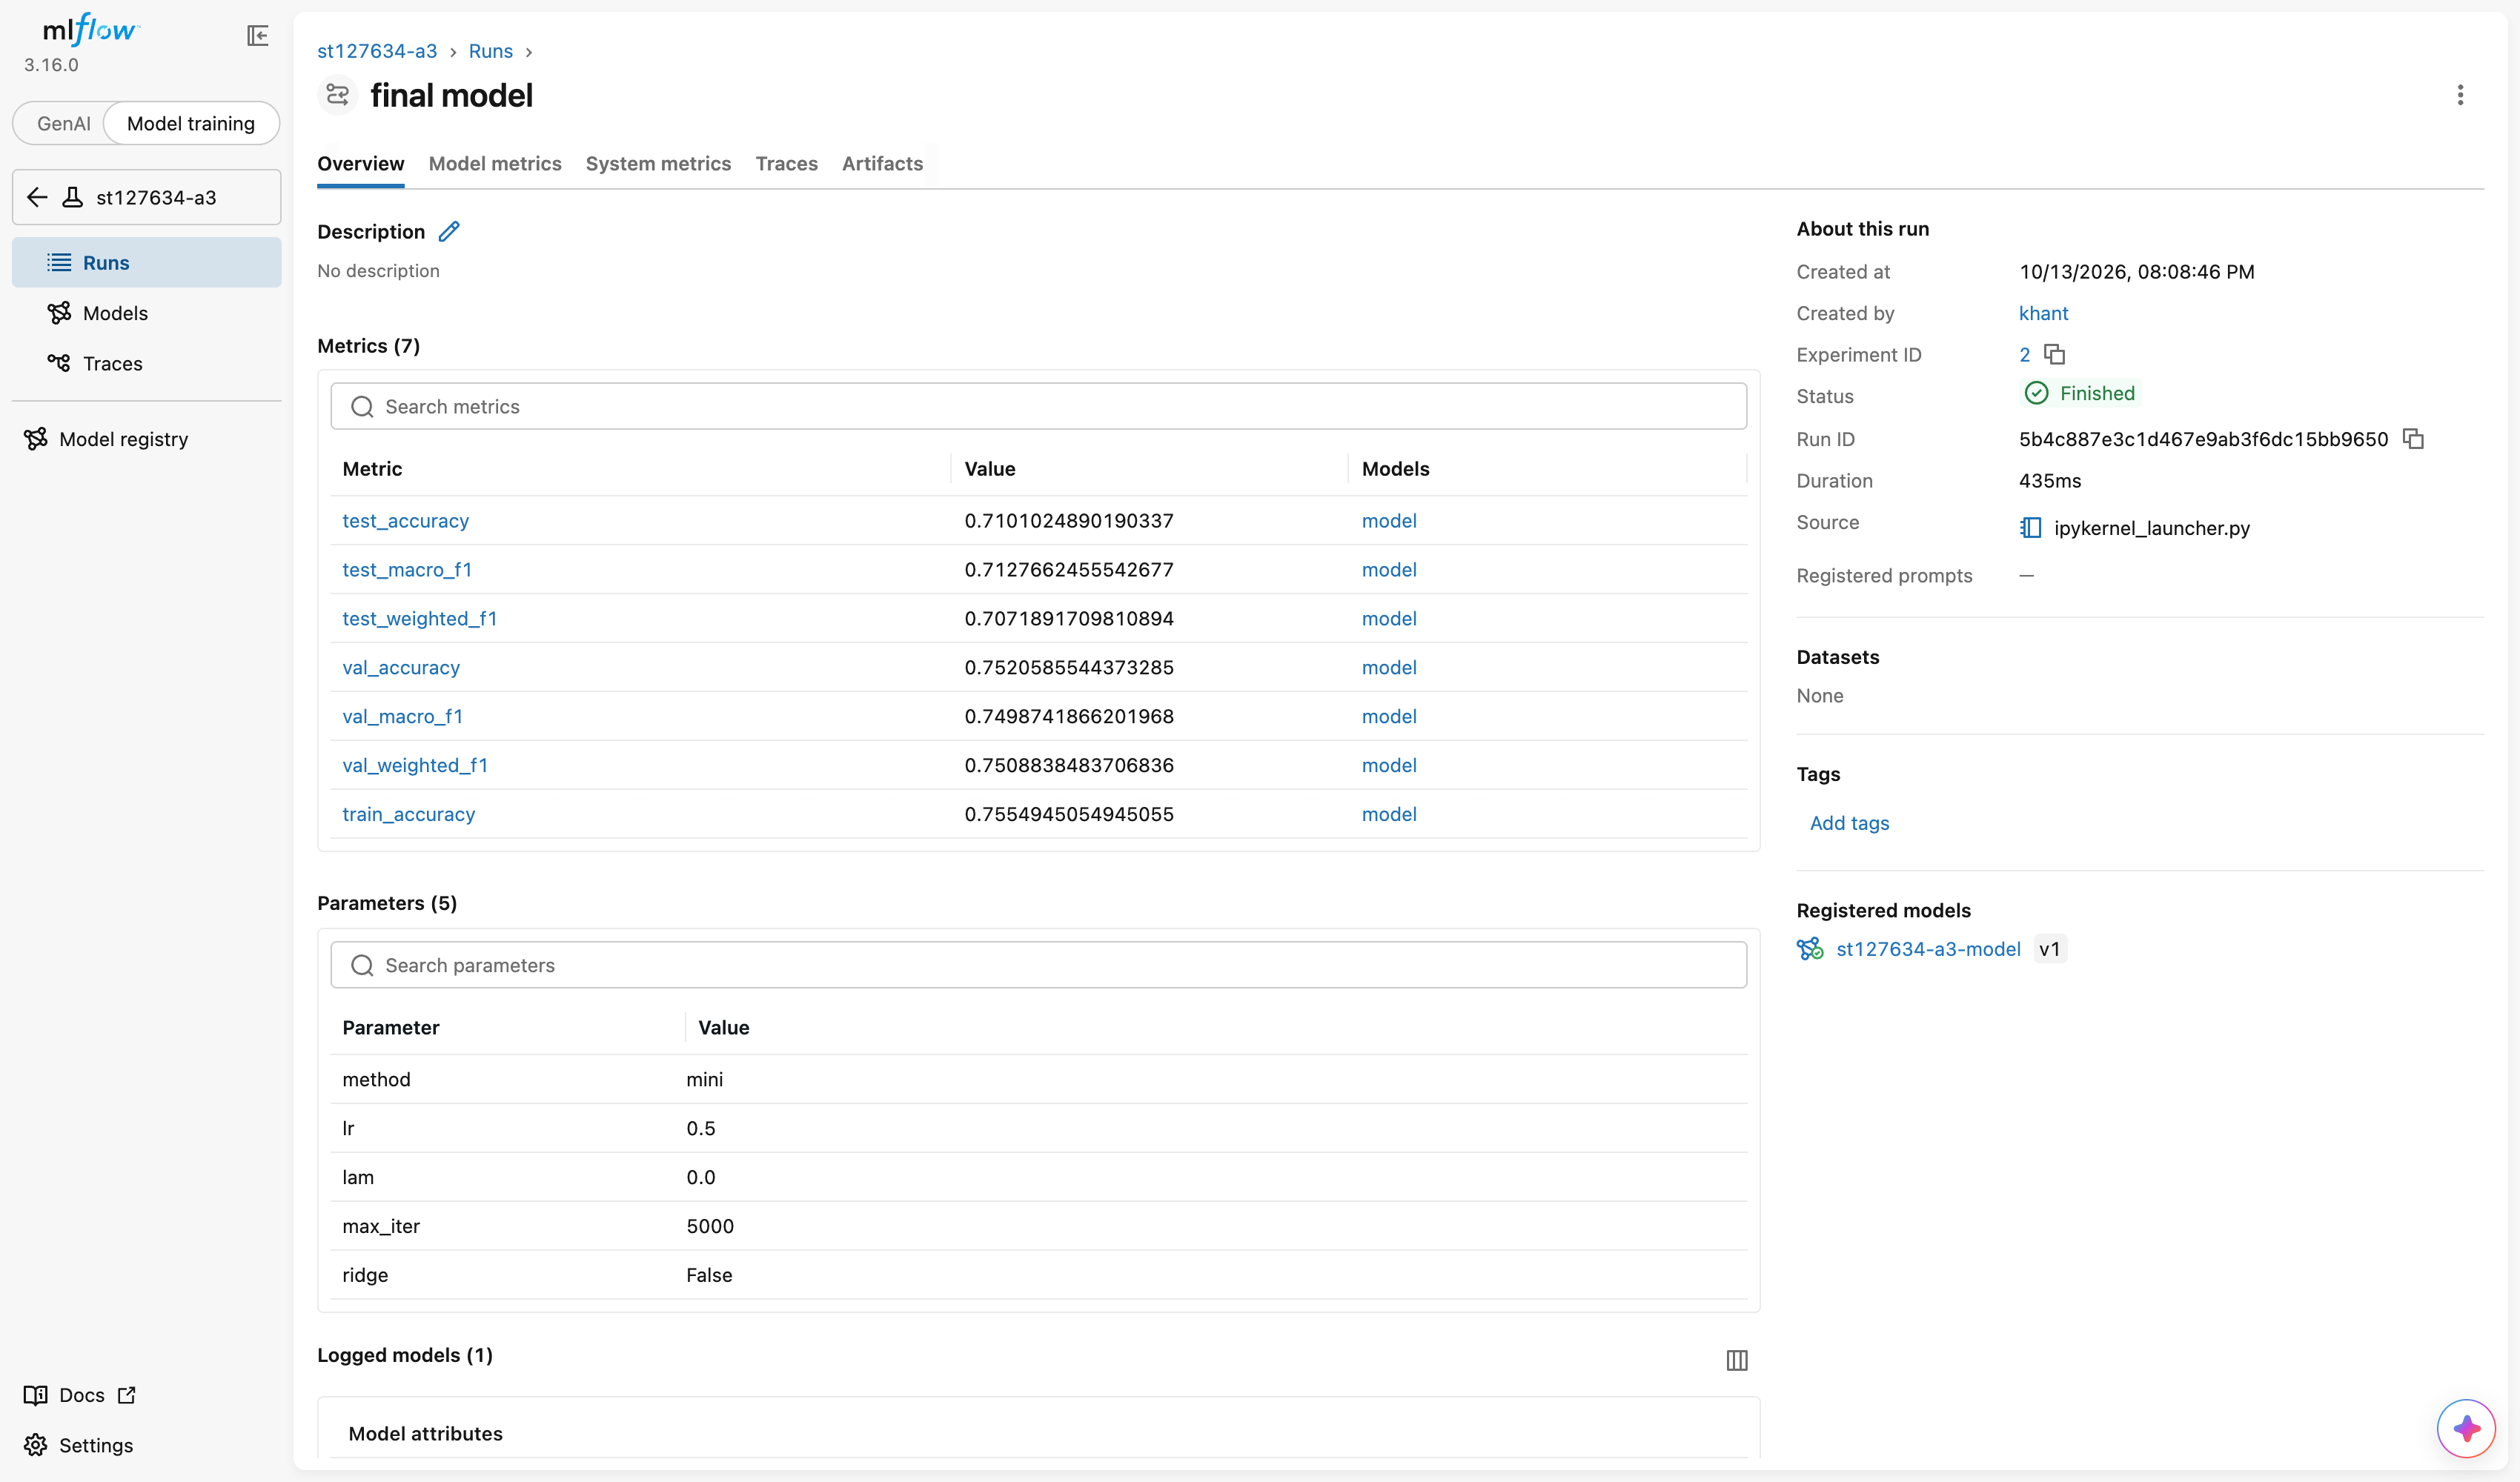

**The registered model**, version 1 with the `staging` alias.

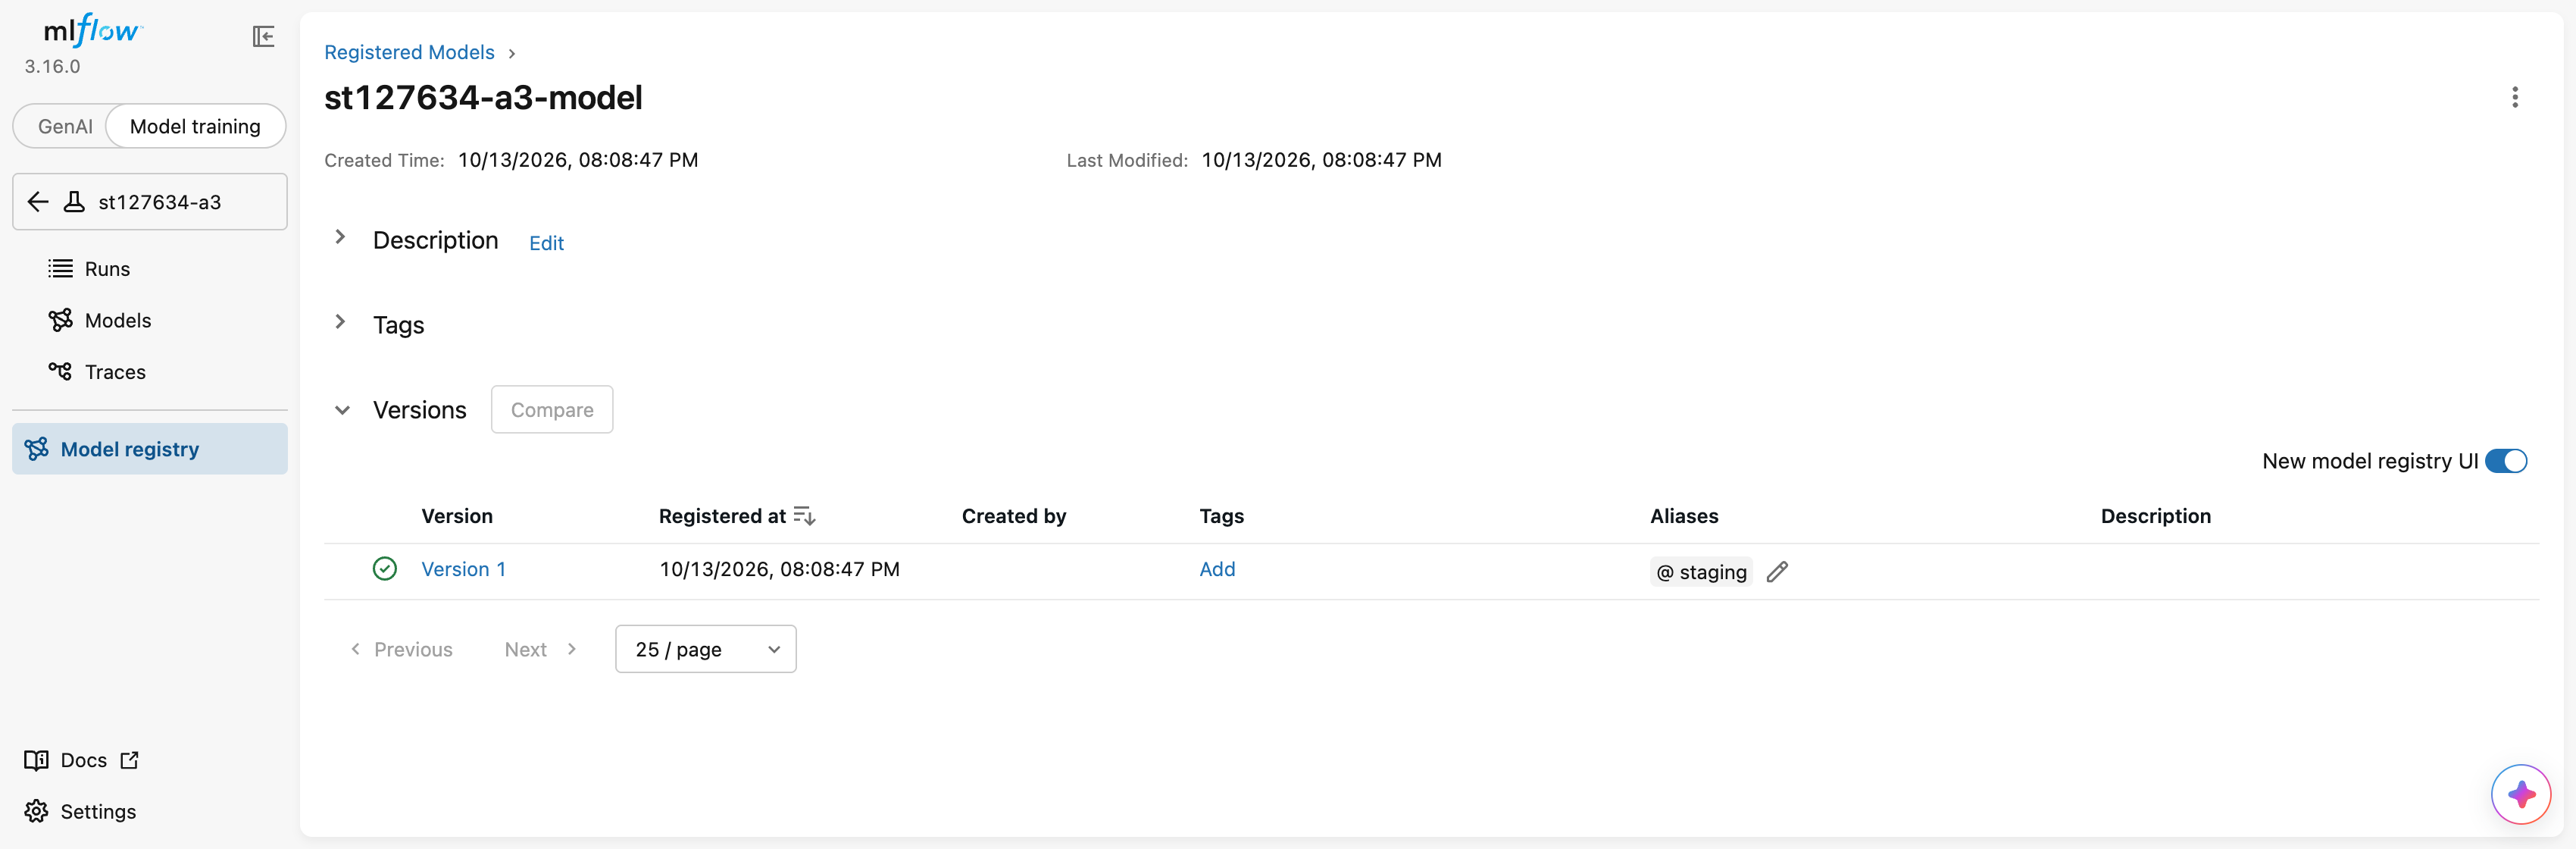

## Report

| model | data | accuracy | macro F1 | weighted F1 |
|---|---|---|---|---|
| mini-batch, lr 0.5, no ridge | validation rows | 0.752 | 0.750 | 0.751 |
| same model | test set | 0.710 | 0.713 | 0.707 |

1. **Price classes.** Cutting at the training quartiles (₹250k, ₹415k, ₹650k) gives four classes of about 1,350 training cars each. Because the classes are almost the same size, macro and weighted scores are nearly equal (test macro F1 0.713, weighted 0.707).
2. **Metrics from scratch.** Our `classification_report` gives exactly the same numbers as sklearn's, on made-up labels and on the test set.
3. **Best run.** Mini-batch with learning rate 0.5 and no ridge had the best validation macro F1 (0.750), but batch at the same learning rate is really a tie (0.748, two cars apart out of 1,093). Learning rate 0.1 scored a little lower (0.740) only because it had not finished learning after 5,000 steps. Stochastic was lowest (0.736): each step follows a single car, so with a fixed learning rate the weights keep bouncing around the best point instead of settling on it.
4. **Ridge did not help.** λ = 0.001 changed the validation score by only a few cars, and λ = 0.01 was the worst run (0.727). Training and validation accuracy are almost the same (0.756 vs 0.752), so the model is not overfitting and there is nothing for ridge to fix. A large λ only pulls the weights away from the best fit.
5. **Test set.** The test macro F1 (0.713) is lower than on the validation rows (0.750). The 8 runs are so close that picking the best of them explains little of this. Most of it is which cars ended up in each set: with only about 1,000 to 1,400 cars in a set, the score moves by a few points from one sample of cars to another.
6. **Where it goes wrong.** 388 of the 396 wrong test predictions are only one class off. The cheapest and most expensive classes are easiest (F1 0.83 and 0.80). The two middle classes are harder (0.64 and 0.58), since they have a neighbour on both sides and many similar cars sit close to the cut points.